# **Physics-Informed Variational Autoencoder with Lightweight State-Space Learning for Real-Time Anomaly Detection in Industrial IoT Systems**

# Load Dataset

In [1]:
import kagglehub

path = kagglehub.dataset_download("rajsharg/synchronized-multivariate-iiot-time-series-dataset")

print("Path to dataset files:", path)

100%|██████████| 24.7M/24.7M [00:00<00:00, 58.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/rajsharg/synchronized-multivariate-iiot-time-series-dataset/versions/1


# Verify Dataset

In [2]:
import os
import pandas as pd

files = os.listdir(path)
print("Files in dataset folder:")
for file in files:
    print(f" - {file}")

csv_files = [f for f in files if f.endswith(".csv")]

if csv_files:
    file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(file_path)

    print(f"\n--- Basic Dataset Overview: {csv_files[0]} ---")
    print(f"Dataset Shape (Rows, Columns): {df.shape}")

    print("\n--- Column Data Types & Missing Values ---")
    print(df.info())

    print("\n--- First 5 Rows ---")
    display(df.head())

    print("\n--- Summary Statistics ---")
    display(df.describe())
else:
    print("\nNo CSV files found in the directory. Checking nested folders:")
    for root, dirs, filenames in os.walk(path):
        for filename in filenames:
            print(os.path.join(root, filename))

Files in dataset folder:
 - Synchronized multivariate IIoT time-series dataset.csv

--- Basic Dataset Overview: Synchronized multivariate IIoT time-series dataset.csv ---
Dataset Shape (Rows, Columns): (172803, 117)

--- Column Data Types & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172803 entries, 0 to 172802
Columns: 117 entries, Timestamp to 3_AIT_005_PV
dtypes: float64(115), int64(1), object(1)
memory usage: 154.3+ MB
None

--- First 5 Rows ---


,Timestamp,Temperature,Pressure,Flow_Rate,Vibration,Current,Voltage,Actuator_State,Control_Signal,Water_Level,...,2A_AIT_004_PV,2B_AIT_001_PV,2B_AIT_002_PV,2B_AIT_003_PV,2B_AIT_004_PV,3_AIT_001_PV,3_AIT_002_PV,3_AIT_003_PV,3_AIT_004_PV,3_AIT_005_PV
0,2017-10-09 00:00:00,30.029878,338.490573,0.408897,0.031275,4.723548,416.161280,0.201215,0.272963,67.592922,...,473.890,0.188477,8.96011,8.69146,475.488,0.0,8279.1,11.52800,-65.9686,0.755703
1,2017-10-09 00:00:00,29.852818,323.593358,0.262464,0.019999,4.426014,415.059218,0.198237,0.117330,77.488024,...,474.570,0.191406,9.10618,8.69100,474.014,0.0,8279.1,7.00437,650.1410,0.452445
2,2017-10-09 00:00:00,30.570057,358.014140,0.771855,0.034519,5.331686,413.615167,0.189128,0.211992,76.973700,...,477.959,0.191406,9.22186,8.64049,475.277,0.0,8279.1,11.86130,514.4350,0.742821
3,2017-10-09 00:00:00,30.176216,330.661823,0.234777,0.014385,4.174923,415.709929,0.003260,0.270775,61.429268,...,482.521,0.189453,9.01097,8.60359,483.900,0.0,8279.1,29.85230,-709.6220,0.723472
4,2017-10-09 00:00:00,30.007146,328.744677,0.207263,0.021685,4.317933,416.242067,0.070375,0.158990,70.308597,...,479.479,0.191406,9.17078,8.64072,476.740,0.0,8279.1,0.00000,1406.3200,0.729929



--- Summary Statistics ---


,Temperature,Pressure,Flow_Rate,Vibration,Current,Voltage,Actuator_State,Control_Signal,Water_Level,Chemical_Quality,...,2A_AIT_004_PV,2B_AIT_001_PV,2B_AIT_002_PV,2B_AIT_003_PV,2B_AIT_004_PV,3_AIT_001_PV,3_AIT_002_PV,3_AIT_003_PV,3_AIT_004_PV,3_AIT_005_PV
count,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,...,172803.000000,172803.000000,172803.000000,172803.000000,172803.000000,172803.0,1.728030e+05,172803.000000,172803.000000,172803.000000
mean,30.531114,338.486051,0.461027,0.032428,5.312162,414.352085,0.144884,0.239094,70.553405,0.547385,...,476.318913,0.195526,4427.946895,8.609683,478.068475,0.0,8.279100e+03,10.452266,539.798452,0.653768
std,1.007471,16.385651,0.266145,0.020854,1.698218,1.235964,0.129058,0.085692,7.694411,0.370918,...,5.034866,0.007606,4035.247854,0.053415,4.055189,0.0,1.116135e-08,9.766727,678.194054,0.126931
min,28.911881,176.650565,0.050000,0.005000,3.720572,407.081031,0.000000,0.000000,21.041082,0.000000,...,462.828000,0.177734,8.647870,8.509690,466.003000,0.0,8.279100e+03,0.000000,-1242.590000,0.336695
25%,29.856085,330.547418,0.255270,0.019271,4.345590,413.786331,0.057567,0.183505,65.214064,0.155155,...,473.711000,0.190430,9.037640,8.572190,475.196000,0.0,8.279100e+03,1.276110,30.531800,0.672303
50%,30.463935,336.792640,0.364362,0.026595,4.684805,414.550751,0.127510,0.239346,71.931880,0.785854,...,476.431000,0.195313,8099.000000,8.604060,477.322000,0.0,8.279100e+03,7.299310,628.228000,0.716923
75%,30.871970,345.204260,0.572583,0.036260,5.143952,415.177276,0.215180,0.272813,76.495168,0.892111,...,479.498000,0.203125,8114.610000,8.652710,480.184000,0.0,8.279100e+03,17.839000,1012.860000,0.729963
max,35.961597,424.925484,2.344633,0.163615,15.310613,418.469200,1.000000,0.853178,86.909298,1.000000,...,487.998000,0.207031,8128.000000,8.742210,489.807000,0.0,8.279100e+03,39.035700,1846.820000,0.891277


# View Columns

In [3]:
print("All columns:")
for col in df.columns:
    print(col)

All columns:
Timestamp
Temperature
Pressure
Flow_Rate
Vibration
Current
Voltage
Actuator_State
Control_Signal
Water_Level
Chemical_Quality
Pump_Speed
Leak_Diff_Pressure
Required_Flow
Attack_Label
2_DPIT_001_PV
2_PIC_003_CO
2_PIC_003_PV
2_PIC_003_SP
2_PIT_001_PV
2_PIT_002_PV
2_PIT_003_PV
1_FIT_001_PV
2_FIT_001_PV
2_FIT_002_PV
2_FIT_003_PV
2_FQ_101_PV
2_FQ_201_PV
2_FQ_301_PV
2_FQ_401_PV
2_FQ_501_PV
2_FQ_601_PV
3_FIT_001_PV
1_LT_001_PV
2_LT_001_PV
2_LT_002_PV
3_LT_001_PV
1_MV_001_STATUS
1_MV_002_STATUS
1_MV_003_STATUS
1_MV_004_STATUS
1_P_001_STATUS
1_P_002_STATUS
1_P_003_STATUS
1_P_004_STATUS
1_P_005_STATUS
1_P_006_STATUS
2_MCV_007_CO
2_MCV_101_CO
2_MCV_201_CO
2_MCV_301_CO
2_MCV_401_CO
2_MCV_501_CO
2_MCV_601_CO
2_MV_001_STATUS
2_MV_002_STATUS
2_MV_003_STATUS
2_MV_004_STATUS
2_MV_005_STATUS
2_MV_006_STATUS
2_MV_009_STATUS
2_MV_101_STATUS
2_MV_201_STATUS
2_MV_301_STATUS
2_MV_401_STATUS
2_MV_501_STATUS
2_MV_601_STATUS
2_P_001_STATUS
2_P_002_STATUS
2_P_003_STATUS
2_P_004_STATUS
2_SV_101_STATU

# Preprocess

# Robust Scaling + Temporal Interpolation + Sliding-Window Segmentation

In [4]:
import numpy as np,pandas as pd
from sklearn.preprocessing import RobustScaler

df=pd.read_csv(file_path)
df["Timestamp"]=pd.to_datetime(df["Timestamp"],errors="coerce")
df=df.sort_values("Timestamp").reset_index(drop=True)
df=df.replace([np.inf,-np.inf],np.nan)

feature_cols=[c for c in df.select_dtypes(include=np.number).columns if c!="Attack_Label"]

df[feature_cols]=df[feature_cols].interpolate(
    method="linear",limit=10,limit_direction="both"
).fillna(df[feature_cols].median())

scaler=RobustScaler(quantile_range=(5,95))
df[feature_cols]=scaler.fit_transform(df[feature_cols]).astype(np.float32)
df[feature_cols]=df[feature_cols].clip(-10,10)

values=df[feature_cols].to_numpy(np.float32)
labels=df["Attack_Label"].to_numpy(np.int8)

normal_idx=np.where(labels==0)[0]
attack_idx=np.where(labels==1)[0]

rng=np.random.default_rng(42)
attack_idx=rng.choice(attack_idx,len(normal_idx),replace=False)

idx=np.concatenate([normal_idx,attack_idx])
rng.shuffle(idx)

values=values[idx]
labels=labels[idx]

window_size=60
n=len(values)-window_size+1

X=np.empty((n,window_size,len(feature_cols)),np.float32)
y=np.empty(n,np.int8)

for i in range(n):
    X[i]=values[i:i+window_size]
    y[i]=labels[i+window_size-1]

print("Features:",len(feature_cols))
print("classes:",pd.Series(labels).value_counts().sort_index().to_dict())
print("Balanced rows:",len(values))
print("Temporal windows:",X.shape)
print("Window labels:",y.shape)

Features: 115
classes: {0: 9977, 1: 9977}
Balanced rows: 19954
Temporal windows: (19895, 60, 115)
Window labels: (19895,)


# Physics-Informed Feature Construction

In [5]:
feature_idx={c:i for i,c in enumerate(feature_cols)}

physics_features=np.empty((X.shape[0],X.shape[1],4),dtype=np.float32)

physics_features[:,:,0]=np.abs(
    X[:,:,feature_idx["Pressure"]]-X[:,:,feature_idx["Flow_Rate"]]
)

physics_features[:,:,1]=np.abs(
    X[:,:,feature_idx["Temperature"]]-X[:,:,feature_idx["Water_Level"]]
)

physics_features[:,:,2]=np.abs(
    X[:,:,feature_idx["Pump_Speed"]]-X[:,:,feature_idx["Vibration"]]
)

physics_features[:,:,3]=np.abs(
    X[:,:,feature_idx["Voltage"]]-X[:,:,feature_idx["Current"]]
)

physics_cols=["Pressure_Flow_Residual","Temperature_Energy_Residual",
              "Speed_Vibration_Residual","Voltage_Current_Residual"]

print("Sensor windows:",X.shape)
print("Physics residual windows:",physics_features.shape)
print("Physics features:",physics_cols)

Sensor windows: (19895, 60, 115)
Physics residual windows: (19895, 60, 4)
Physics features: ['Pressure_Flow_Residual', 'Temperature_Energy_Residual', 'Speed_Vibration_Residual', 'Voltage_Current_Residual']


# Split Dataset

In [6]:
import gc

n=len(X)
train_end=int(n*0.70)
val_end=int(n*0.85)

train_idx=np.arange(0,train_end)
val_idx=np.arange(train_end,val_end)
test_idx=np.arange(val_end,n)

print("Train:",len(train_idx))
print("Validation:",len(val_idx))
print("Test:",len(test_idx))
print("Train classes:",pd.Series(y[train_idx]).value_counts().sort_index().to_dict())
print("Validation classes:",pd.Series(y[val_idx]).value_counts().sort_index().to_dict())
print("Test classes:",pd.Series(y[test_idx]).value_counts().sort_index().to_dict())

gc.collect()

Train: 13926
Validation: 2984
Test: 2985
Train classes: {0: 6991, 1: 6935}
Validation classes: {0: 1490, 1: 1494}
Test classes: {0: 1470, 1: 1515}


0

# Build Model

# Physics-Constrained Variational Autoencoder

# Physics-Guided Mamba State-Space Encoder

# Latent Reconstruction + Physics Residual Analysis

#  Uncertainty-Aware Adaptive Anomaly Scoring

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,Model
import numpy as np,gc

tf.keras.backend.clear_session();gc.collect()
tf.random.set_seed(42);np.random.seed(42)

latent_dim=64
batch_size=128
epochs=100
beta=.0003
lambda_phys=.10
lambda_latent=.03
lambda_cls=.80
lambda_unc=.03

class Sampling(layers.Layer):
    def call(self,x):
        m,v=x
        v=tf.clip_by_value(v,-4.,4.)
        return m+tf.exp(.5*v)*tf.random.normal(tf.shape(m))

class PG_Mamba(layers.Layer):
    def __init__(self,d):
        super().__init__()
        self.i=layers.Dense(d,activation="tanh")
        self.dt=layers.Dense(d,activation="sigmoid")
        self.g=layers.Dense(d,activation="sigmoid")
        self.s=layers.Dense(d,activation="tanh")
        self.p=layers.Dense(d,activation="sigmoid")
        self.o=layers.Dense(d,activation="tanh")
        self.n=layers.LayerNormalization()

    def call(self,x,p):
        u=self.i(x);p=self.p(p)
        s=tf.zeros_like(u[:,0,:]);o=[]
        for t in range(60):
            q=u[:,t];r=p[:,t]
            d=.05*self.dt(q)
            s=(1-d)*s+d*self.s(q+r)
            g=self.g(q+r)
            s=g*s+(1-g)*q
            o.append(s)
        return self.n(self.o(tf.stack(o,1))+x)

class PCVAE(Model):
    def __init__(self):
        super().__init__()
        self.e1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.e2=layers.Conv1D(64,5,padding="same",activation="tanh")
        self.e3=layers.Conv1D(64,7,padding="same",activation="tanh")
        self.n=layers.LayerNormalization()
        self.zm=layers.Dense(latent_dim,activation="tanh")
        self.zv=layers.Dense(latent_dim,activation="tanh")
        self.samp=Sampling()
        self.p1=layers.Dense(32,activation="tanh")
        self.p2=layers.Dense(latent_dim,activation="tanh")
        self.f=layers.Dense(latent_dim,activation="tanh")
        self.m=PG_Mamba(latent_dim)
        self.tp=layers.Dense(latent_dim,activation="tanh")
        self.g=layers.Dense(latent_dim,activation="sigmoid")
        self.lp=layers.Dense(4)
        self.r1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.r2=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.rec=layers.Conv1D(len(feature_cols),1)
        self.prec=layers.Conv1D(4,1)
        self.unc=layers.Conv1D(1,1,activation="sigmoid")

        self.pool=layers.GlobalAveragePooling1D()
        self.cls1=layers.Dense(64,activation="tanh")
        self.cls2=layers.Dense(32,activation="tanh")
        self.drop=layers.Dropout(.10)
        self.cls=layers.Dense(1,activation="sigmoid")

    def call(self,x,training=False):
        x,p=x
        a=self.e1(x)
        h=self.n(a+self.e2(a)+self.e3(a))
        m,v=self.zm(h),self.zv(h)
        z=self.samp([m,v])
        p=self.p2(self.p1(p))
        z=self.f(layers.Concatenate()([z,p]))
        t=self.m(z,p)
        q=self.tp(p)
        g=self.g(layers.Concatenate()([t,q]))
        h=g*t+(1-g)*q
        lp=self.lp(h)

        r=self.r2(self.r1(h))
        rec=self.rec(r)
        prec=self.prec(r)
        unc=self.unc(r)

        c1=self.pool(h)
        c2=h[:,-1,:]
        c=layers.Concatenate()([c1,c2])
        c=self.cls1(c)
        c=self.drop(c,training=training)
        c=self.cls2(c)
        c=self.drop(c,training=training)
        cls=self.cls(c)

        return rec,prec,unc,m,v,h,lp,cls

class Trainer(Model):
    def __init__(self,b):
        super().__init__()
        self.b=b
        self.ms=[tf.keras.metrics.Mean(n) for n in
                 ["loss","reconstruction","physics","kl",
                  "latent_physics","classification","uncertainty"]]

    @property
    def metrics(self):
        return self.ms

    def call(self,inputs,training=False):
        return self.b(inputs,training=training)

    def calc(self,x,p,y,train=False):
        rec,pr,u,m,v,h,lp,cls=self.b(
            [x,p],training=train
        )

        r=tf.reduce_mean(tf.square(x-rec))
        ph=tf.reduce_mean(tf.square(p-pr))
        l=tf.reduce_mean(tf.square(p-lp))

        v=tf.clip_by_value(v,-4.,4.)
        k=-.5*tf.reduce_mean(
            1+v-tf.square(m)-tf.exp(v)
        )

        y=tf.cast(y,tf.float32)
        pred=tf.squeeze(cls,-1)

        ce=tf.keras.backend.binary_crossentropy(y,pred)
        pt=tf.where(y>0,pred,1-pred)

        c=tf.reduce_mean(
            .75*tf.pow(1-pt,2.)*ce
        )

        residual=tf.reduce_mean(
            tf.square(x-rec),axis=[1,2]
        )

        target=tf.stop_gradient(
            tf.sigmoid(
                5.*(
                    residual-
                    tf.reduce_mean(residual)
                )
            )
        )

        unc_loss=tf.reduce_mean(
            tf.square(
                tf.squeeze(u,-1)-target[:,None]
            )
        )

        total=(
            r+
            lambda_phys*ph+
            lambda_latent*l+
            beta*k+
            lambda_cls*c+
            lambda_unc*unc_loss
        )

        return total,r,ph,k,l,c,unc_loss

    def train_step(self,d):
        (x,p),y=d

        with tf.GradientTape() as tape:
            vals=self.calc(x,p,y,True)

        grads=tape.gradient(
            vals[0],
            self.b.trainable_variables
        )

        grads=[
            tf.clip_by_norm(g,.5)
            if g is not None else None
            for g in grads
        ]

        self.optimizer.apply_gradients(
            (g,v)
            for g,v in zip(
                grads,self.b.trainable_variables
            )
            if g is not None
        )

        for m,v in zip(self.ms,vals):
            m.update_state(v)

        return {
            m.name:m.result()
            for m in self.ms
        }

    def test_step(self,d):
        (x,p),y=d
        vals=self.calc(x,p,y,False)

        for m,v in zip(self.ms,vals):
            m.update_state(v)

        return {
            m.name:m.result()
            for m in self.ms
        }

def gen(X,P,y,a,b):
    for i in range(a,b,batch_size):
        j=min(i+batch_size,b)
        yield (X[i:j],P[i:j]),y[i:j]

spec=(
    (
        tf.TensorSpec(
            (None,60,len(feature_cols)),tf.float32
        ),
        tf.TensorSpec(
            (None,60,4),tf.float32
        )
    ),
    tf.TensorSpec((None,),tf.int8)
)

train_ds=tf.data.Dataset.from_generator(
    lambda:gen(
        X,physics_features,y,
        0,train_end
    ),
    output_signature=spec
).repeat().prefetch(1)

val_ds=tf.data.Dataset.from_generator(
    lambda:gen(
        X,physics_features,y,
        train_end,val_end
    ),
    output_signature=spec
).repeat().prefetch(1)

steps_per_epoch=int(
    np.ceil(train_end/batch_size)
)

validation_steps=int(
    np.ceil(
        (val_end-train_end)/batch_size
    )
)

model=Trainer(PCVAE())

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        1e-4,clipnorm=.5
    )
)

print("model built successfully")

model built successfully


# Train Model

In [ ]:
import numpy as np
import tensorflow as tf

steps_per_epoch = int(np.ceil(train_end / batch_size))
validation_steps = int(np.ceil((val_end - train_end) / batch_size))

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=.5, patience=3, min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 142s 681ms/step - classification: 0.1289 - kl: 0.3175 - latent_physics: 0.5181 - loss: 0.4991 - physics: 0.2849 - reconstruction: 0.3511 - uncertainty: 0.0221 - val_classification: 0.1017 - val_kl: 0.3338 - val_latent_physics: 0.2591 - val_loss: 0.3864 - val_physics: 0.1625 - val_reconstruction: 0.2804 - val_uncertainty: 0.0194 - learning_rate: 1.0000e-04
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - classification: 0.1011 - kl: 0.3313 - latent_physics: 0.1815 - loss: 0.3551 - physics: 0.1153 - reconstruction: 0.2569 - uncertainty: 0.0094 - val_classification: 0.0864 - val_kl: 0.3272 - val_latent_physics: 0.1339 - val_loss: 0.3178 - val_physics: 0.0859 - val_reconstruction: 0.2359 - val_uncertainty: 0.0042 - learning_rate: 1.0000e-04
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - classification: 0.0810 - kl: 0.3301 - latent_physics: 0.1066 - loss: 0.2958 - physics: 0.0650 - reconstruction: 0.2211 - uncertainty: 0.0040 - val_cl

# Model History

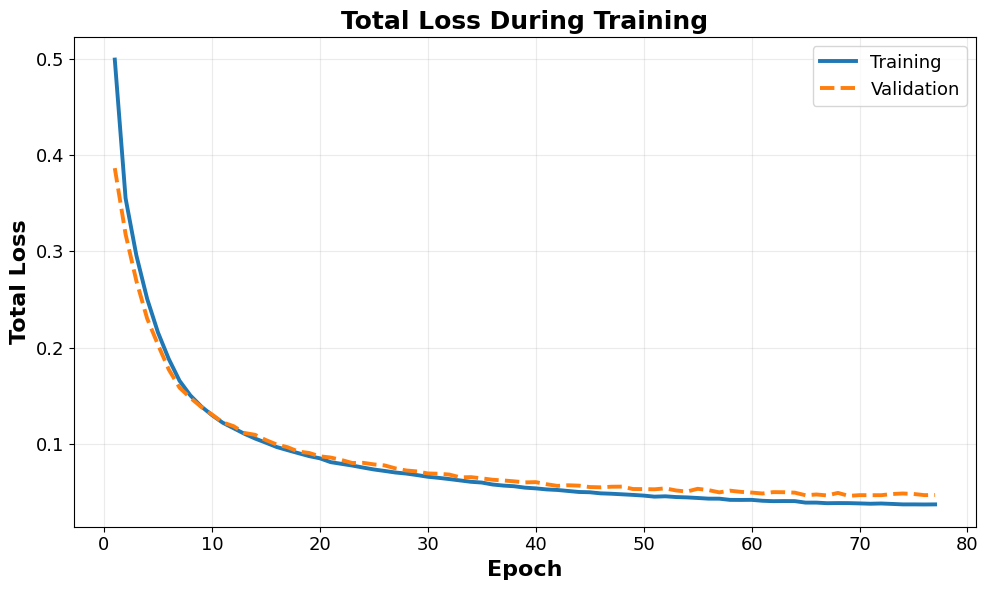

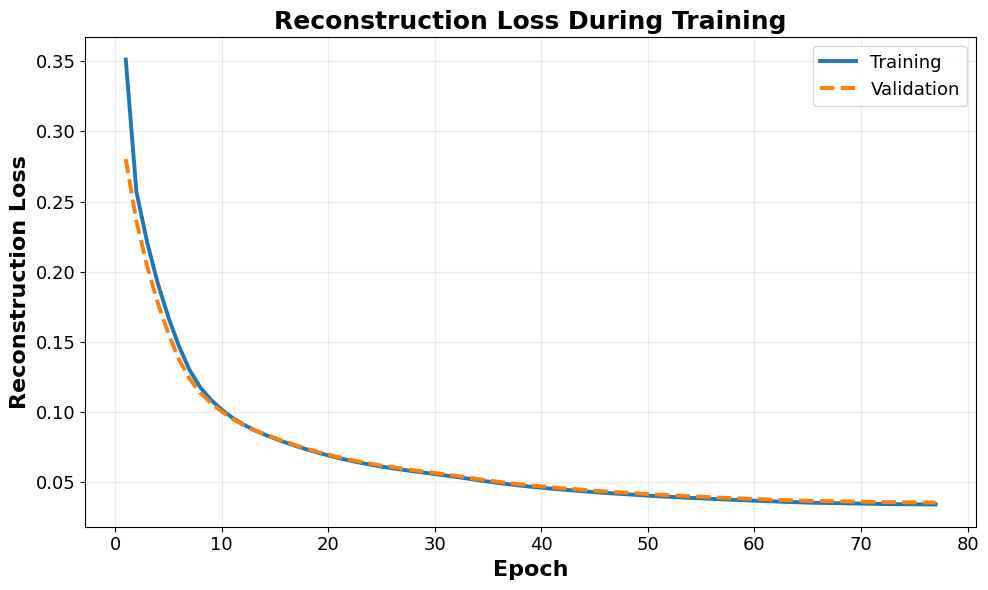

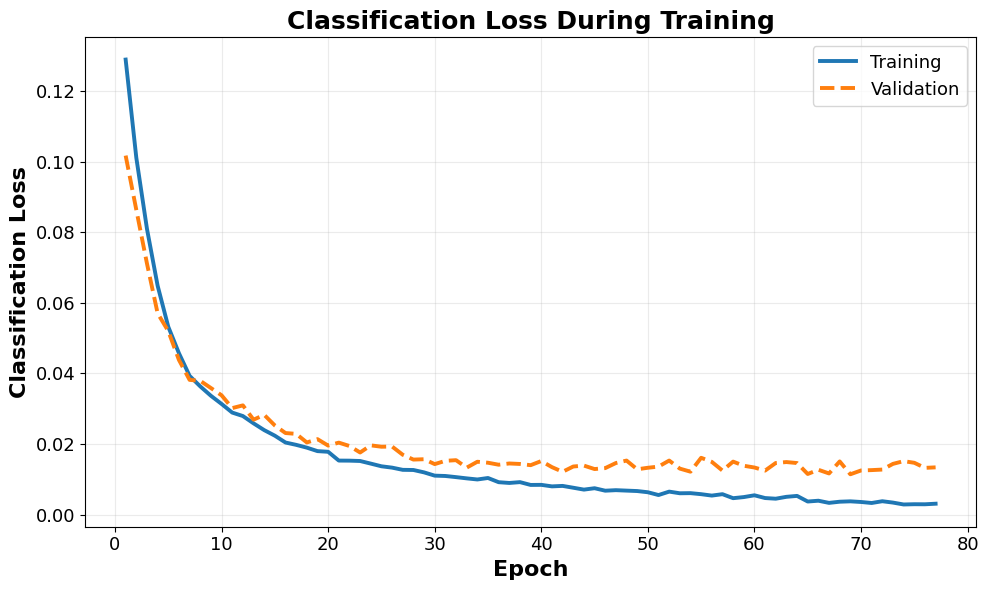

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

h=history.history
ep=np.arange(1,len(h["loss"])+1)

plots=[
    ("loss","val_loss","Total Loss"),
    ("reconstruction","val_reconstruction","Reconstruction Loss"),
    ("classification","val_classification","Classification Loss")
]

for tr,va,title in plots:
    plt.figure(figsize=(10,6))
    plt.plot(ep,h[tr],linewidth=2.8,label="Training")
    plt.plot(ep,h[va],linewidth=2.8,linestyle="--",label="Validation")
    plt.xlabel("Epoch",fontsize=16,fontweight="bold")
    plt.ylabel(title,fontsize=16,fontweight="bold")
    plt.title(title+" During Training",fontsize=18,fontweight="bold")
    plt.tick_params(axis="both",labelsize=13)
    plt.grid(True,alpha=.25)
    plt.legend(fontsize=13)
    plt.tight_layout()
    plt.show()
    plt.close()

# Confusion Matrix

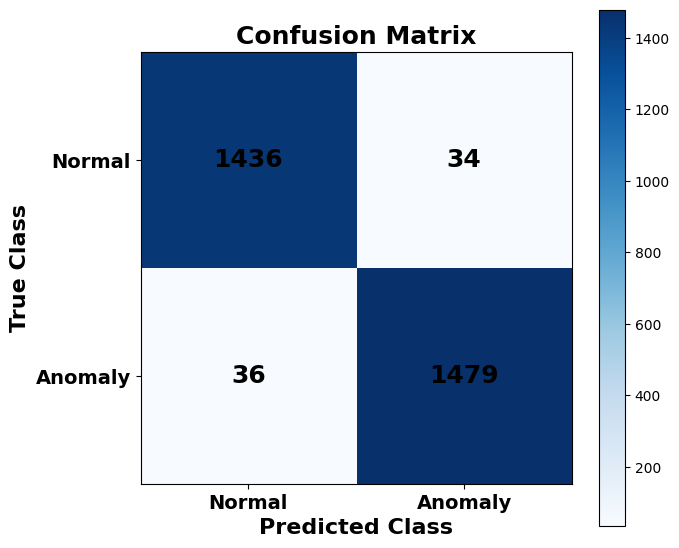

Confusion Matrix:
[[1436   34]
 [  36 1479]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

rec,pr,u,m,v,h,lp,cls=model(
    [X[test_idx],physics_features[test_idx]],
    training=False
)

y_true=y[test_idx]
y_pred=(tf.squeeze(cls,-1).numpy()>=0.5).astype(np.int8)

cm=confusion_matrix(y_true,y_pred)

plt.figure(figsize=(7,6))
plt.imshow(cm,cmap="Blues")
plt.xticks([0,1],["Normal","Anomaly"],fontsize=14,fontweight="bold")
plt.yticks([0,1],["Normal","Anomaly"],fontsize=14,fontweight="bold")
plt.xlabel("Predicted Class",fontsize=16,fontweight="bold")
plt.ylabel("True Class",fontsize=16,fontweight="bold")
plt.title("Confusion Matrix",fontsize=18,fontweight="bold")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j,i,str(cm[i,j]),
                 ha="center",va="center",
                 fontsize=18,fontweight="bold")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

# TEMPORAL ANOMALY LOCALIZATION

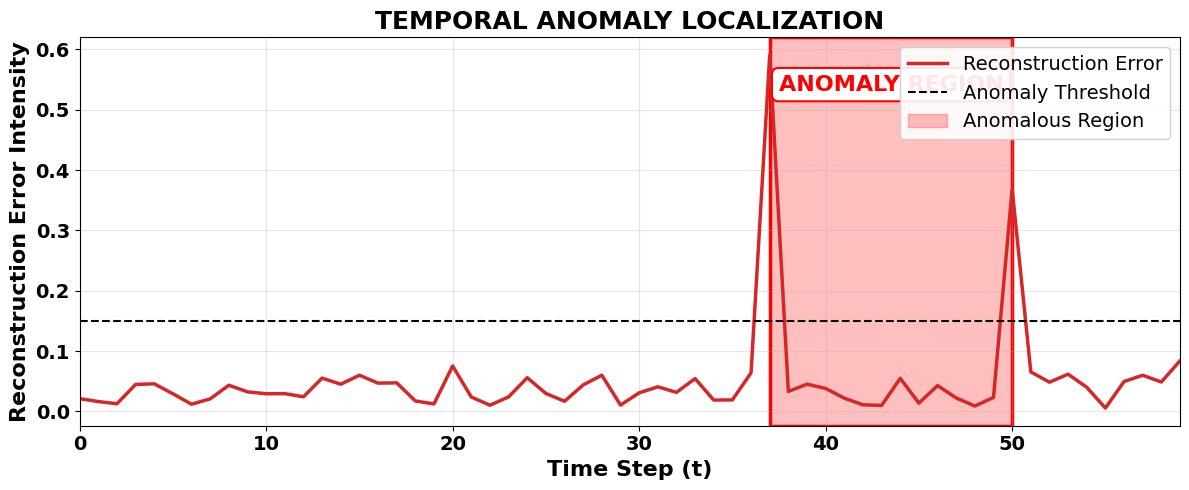

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

_, _, _, _, _, _, _, cls_all = model(
    [X[test_idx], physics_features[test_idx]],
    training=False
)
raw_probs_all = tf.squeeze(cls_all, -1).numpy()
sample_idx = int(np.argmax(raw_probs_all))

x_sample = X[test_idx][sample_idx:sample_idx+1]
p_sample = physics_features[test_idx][sample_idx:sample_idx+1]
rec, pr, u, m, v, h, lp, cls = model([x_sample, p_sample], training=False)

time_steps = np.arange(60)
rec_error_per_step = tf.reduce_mean(
    tf.square(x_sample[0] - rec[0]), axis=-1
).numpy()

threshold = 0.15
anom_steps = np.where(rec_error_per_step > threshold)[0]

plt.figure(figsize=(12, 5))

plt.plot(
    time_steps,
    rec_error_per_step,
    color="#d62728",
    linewidth=2.5,
    label="Reconstruction Error"
)

plt.axhline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Anomaly Threshold"
)

if len(anom_steps) > 0:
    t_min, t_max = anom_steps[0], anom_steps[-1]

    plt.axvspan(
        t_min,
        t_max,
        color="red",
        alpha=0.25,
        label="Anomalous Region"
    )

    plt.axvspan(
        t_min,
        t_max,
        facecolor="none",
        edgecolor="red",
        linewidth=2.5
    )

    plt.text(
        (t_min + t_max) / 2,
        max(rec_error_per_step) * 0.9,
        "ANOMALY REGION",
        color="red",
        fontweight="bold",
        fontsize=16,
        ha="center",
        bbox=dict(
            boxstyle="round,pad=0.3",
            fc="white",
            ec="red",
            lw=1.5
        )
    )

plt.title(
    "TEMPORAL ANOMALY LOCALIZATION",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Time Step (t)",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel(
    "Reconstruction Error Intensity",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

plt.xlim(0, 59)
plt.grid(True, alpha=0.3)

plt.legend(
    loc="upper right",
    framealpha=0.9,
    fontsize=14
)

plt.tight_layout()
plt.show()

 # ROOT CAUSE ATTRIBUTION

=== Root Cause Analysis | Prob: 0.9956) ===
Temperature         : 0.1416
Pressure            : 0.1459
Flow                : 0.0771
Vibration           : 0.0859
Electrical          : 0.1048
Actuator Control    : 0.1174

Primary Anomaly Cause: PRESSURE


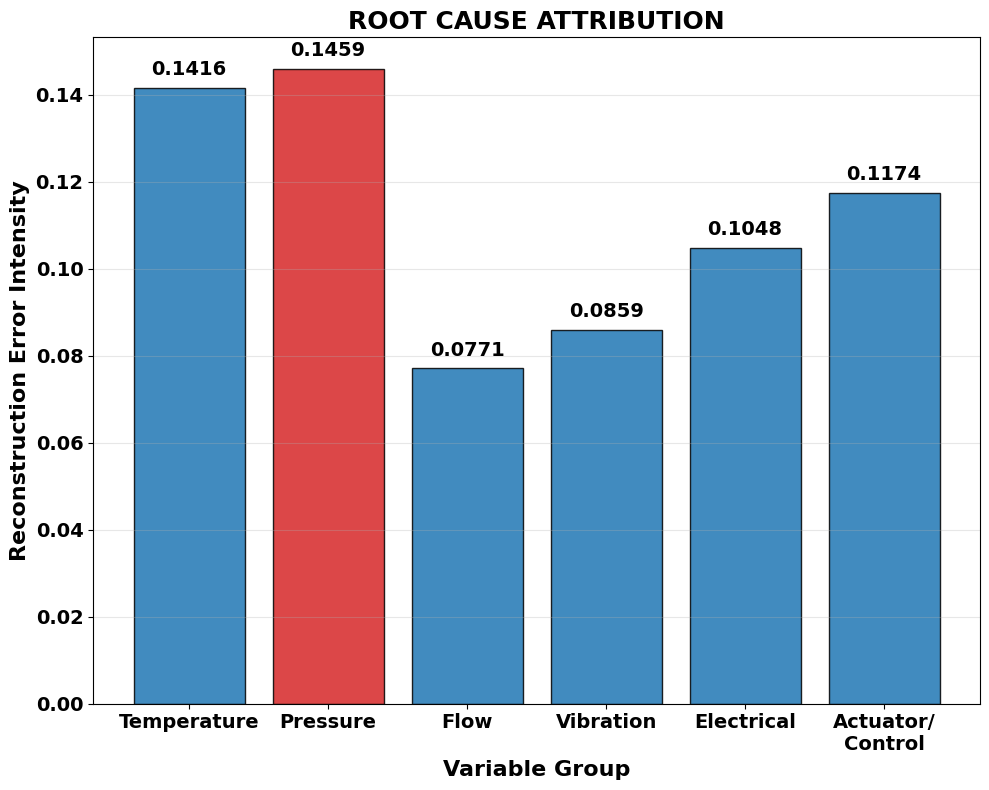

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

feature_groups = {
    "Temperature": [i for i, c in enumerate(feature_cols) if "temp" in c.lower()],
    "Pressure": [i for i, c in enumerate(feature_cols) if "press" in c.lower()],
    "Flow": [i for i, c in enumerate(feature_cols) if "flow" in c.lower()],
    "Vibration": [i for i, c in enumerate(feature_cols) if "vib" in c.lower()],
    "Electrical": [i for i, c in enumerate(feature_cols) if any(k in c.lower() for k in ["volt", "curr", "pwr", "elec"])],
    "Actuator_Control": [i for i, c in enumerate(feature_cols) if any(k in c.lower() for k in ["pos", "ctrl", "act", "valv"])]
}

rec, pr, u, m, v, h, lp, cls = model(
    [X[test_idx], physics_features[test_idx]],
    training=False
)

raw_probs = tf.squeeze(cls, -1).numpy()
high_conf_idx = np.argmax(raw_probs)

high_conf_x = X[test_idx][high_conf_idx:high_conf_idx+1]
high_conf_rec = rec.numpy()[high_conf_idx:high_conf_idx+1]
abs_err_high_conf = np.abs(high_conf_x - high_conf_rec)

group_errors = {}
for group_name, col_indices in feature_groups.items():
    if col_indices:
        group_errors[group_name] = np.mean(abs_err_high_conf[:, :, col_indices])
    else:
        group_errors[group_name] = 0.0

primary_cause = max(group_errors, key=group_errors.get)

print(f"=== Root Cause Analysis | Prob: {raw_probs[high_conf_idx]:.4f}) ===")
for grp, err in group_errors.items():
    print(f"{grp.replace('_', ' '):<20}: {err:.4f}")
print(f"\nPrimary Anomaly Cause: {primary_cause.upper()}")

plt.figure(figsize=(10, 8))

colors = [
    "#d62728" if g == primary_cause else "#1f77b4"
    for g in group_errors.keys()
]

bars = plt.bar(
    [g.replace("_", "/\n") for g in group_errors.keys()],
    list(group_errors.values()),
    color=colors,
    edgecolor="black",
    alpha=0.85
)

plt.title(
    "ROOT CAUSE ATTRIBUTION",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Variable Group",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel(
    "Reconstruction Error Intensity",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(fontsize=14, fontweight="bold")
plt.yticks(fontsize=14, fontweight="bold")

plt.grid(axis="y", alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.002,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# Prediction

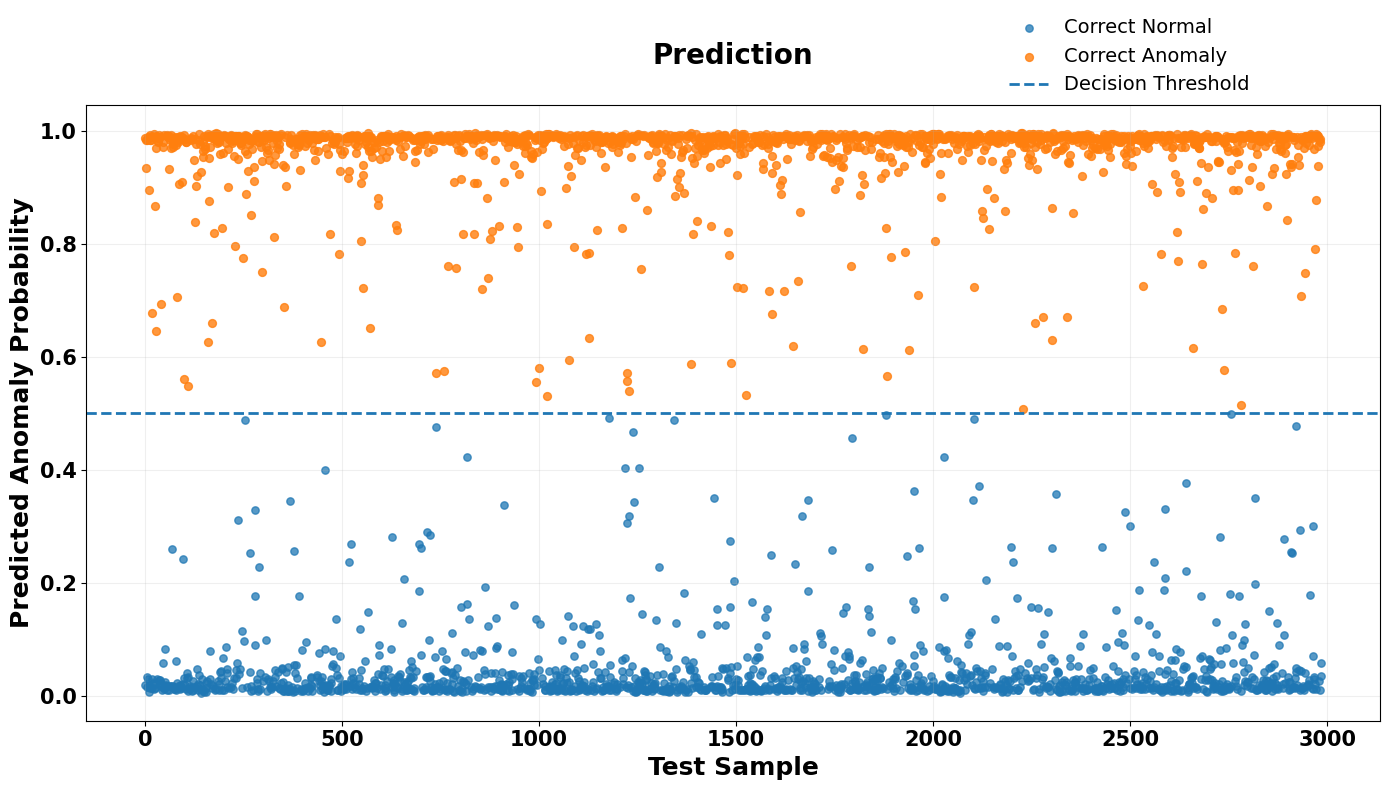

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

rec, pr, u, m, v, h, lp, cls = model(
    [X[test_idx], physics_features[test_idx]],
    training=False
)

prob = tf.squeeze(cls, -1).numpy()
y_pred = (prob >= 0.5).astype(int)
y_true = np.asarray(y)[test_idx].astype(int).reshape(-1)

correct = y_true == y_pred
idx = np.where(correct)[0]

plt.figure(figsize=(14, 8))

plt.scatter(
    idx[y_true[idx] == 0],
    prob[idx[y_true[idx] == 0]],
    s=28,
    alpha=.75,
    label="Correct Normal"
)

plt.scatter(
    idx[y_true[idx] == 1],
    prob[idx[y_true[idx] == 1]],
    s=32,
    alpha=.8,
    label="Correct Anomaly"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Decision Threshold"
)

plt.xlabel(
    "Test Sample",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "Predicted Anomaly Probability",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "\nPrediction\n",
    fontsize=20,
    fontweight="bold"
)

plt.xticks(fontsize=15, fontweight="bold")
plt.yticks(fontsize=15, fontweight="bold")

plt.grid(alpha=.2)

plt.legend(
    fontsize=14,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0.7, 1.17)
)

plt.tight_layout()
plt.show()

# Overall Performance

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,precision_score,recall_score,f1_score,
    roc_auc_score,average_precision_score,balanced_accuracy_score,
    matthews_corrcoef,cohen_kappa_score,confusion_matrix
)

rec,pr,u,m,v,h,lp,cls=model(
    [X[test_idx],physics_features[test_idx]],
    training=False
)

y_true=y[test_idx]
prob=tf.squeeze(cls,-1).numpy()
y_pred=(prob>=0.5).astype(np.int8)

tn,fp,fn,tp=confusion_matrix(
    y_true,y_pred
).ravel()

accuracy=accuracy_score(y_true,y_pred)
precision=precision_score(y_true,y_pred,zero_division=0)
recall=recall_score(y_true,y_pred,zero_division=0)
f1=f1_score(y_true,y_pred,zero_division=0)
auc=roc_auc_score(y_true,prob)
pr_auc=average_precision_score(y_true,prob)
balanced_acc=balanced_accuracy_score(y_true,y_pred)
specificity=tn/(tn+fp) if (tn+fp)>0 else 0
npv=tn/(tn+fn) if (tn+fn)>0 else 0
fpr=fp/(fp+tn) if (fp+tn)>0 else 0
fnr=fn/(fn+tp) if (fn+tp)>0 else 0
mcc=matthews_corrcoef(y_true,y_pred)
kappa=cohen_kappa_score(y_true,y_pred)
gmean=np.sqrt(recall*specificity)

print("Overall Performance")
print("-"*40)
print(f"Accuracy (%)             : {accuracy*100:.2f}")
print(f"Precision (%)            : {precision*100:.2f}")
print(f"Recall / Sensitivity (%) : {recall*100:.2f}")
print(f"Specificity (%)          : {specificity*100:.2f}")
print(f"F1-Score (%)             : {f1*100:.2f}")
print(f"ROC-AUC                  : {auc:.4f}")
print(f"PR-AUC                   : {pr_auc:.4f}")
print(f"MCC                      : {mcc:.4f}")


Overall Performance
----------------------------------------
Accuracy (%)             : 97.79
Precision (%)            : 98.08
Recall / Sensitivity (%) : 97.56
Specificity (%)          : 98.03
F1-Score (%)             : 97.82
ROC-AUC                  : 0.9975
PR-AUC                   : 0.9977
MCC                      : 0.9558


# Comparison techniques

# Physics-Informed VAE

In [ ]:
import tensorflow as tf,numpy as np,gc
from tensorflow.keras import layers,Model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,matthews_corrcoef,confusion_matrix

tf.keras.backend.clear_session();gc.collect()
tf.random.set_seed(42);np.random.seed(42)

latent_dim=48;batch_size=128;epochs=100
beta=.0005;lambda_phys=.15;lambda_latent=.05;lambda_cls=.70;lambda_unc=.03

class S(layers.Layer):
    def call(self,x):
        m,v=x;v=tf.clip_by_value(v,-4.,4.)
        return m+tf.exp(.5*v)*tf.random.normal(tf.shape(m))

class PI(Model):
    def __init__(self):
        super().__init__()
        self.noise=layers.GaussianNoise(.01)
        self.e1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.e2=layers.Conv1D(64,5,padding="same",activation="tanh")
        self.e3=layers.Conv1D(64,7,padding="same",activation="tanh")
        self.n=layers.LayerNormalization()
        self.zm=layers.Dense(latent_dim,activation="tanh")
        self.zv=layers.Dense(latent_dim,activation="tanh")
        self.s=S()
        self.p1=layers.Dense(32,activation="tanh")
        self.p2=layers.Dense(latent_dim,activation="tanh")
        self.f=layers.Dense(latent_dim,activation="tanh")
        self.lp=layers.Dense(4)
        self.r1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.r2=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.rec=layers.Conv1D(len(feature_cols),1)
        self.pr=layers.Conv1D(4,1)
        self.u=layers.Conv1D(1,1,activation="sigmoid")
        self.pool=layers.GlobalAveragePooling1D()
        self.c1=layers.Dense(64,activation="tanh")
        self.c2=layers.Dense(32,activation="tanh")
        self.d=layers.Dropout(.10)
        self.cls=layers.Dense(1,activation="sigmoid")

    def call(self,x,training=False):
        x,p=x
        x=self.noise(x,training=training)
        a=self.e1(x)
        h=self.n(a+self.e2(a)+self.e3(a))
        m,v=self.zm(h),self.zv(h)
        z=self.s([m,v])
        p=self.p2(self.p1(p))
        z=self.f(layers.Concatenate()([z,p]))
        lp=self.lp(z)
        r=self.r2(self.r1(z))
        rec=self.rec(r);pr=self.pr(r);u=self.u(r)
        c=self.pool(z)
        c=self.c1(c);c=self.d(c,training=training)
        c=self.c2(c)
        return rec,pr,u,m,v,z,lp,self.cls(c)

class T(Model):
    def __init__(self,b):
        super().__init__();self.b=b
        self.ms=[tf.keras.metrics.Mean(n) for n in ["loss","reconstruction","physics","kl","latent_physics","classification","uncertainty"]]
    @property
    def metrics(self): return self.ms
    def call(self,x,training=False): return self.b(x,training=training)

    def calc(self,x,p,y,train=False):
        rec,pr,u,m,v,h,lp,cl=self.b([x,p],training=train)
        r=tf.reduce_mean(tf.square(x-rec))
        ph=tf.reduce_mean(tf.square(p-pr))
        l=tf.reduce_mean(tf.square(p-lp))
        v=tf.clip_by_value(v,-4.,4.)
        k=-.5*tf.reduce_mean(1+v-tf.square(m)-tf.exp(v))
        y=tf.cast(y,tf.float32);pred=tf.squeeze(cl,-1)
        ce=tf.keras.backend.binary_crossentropy(y,pred)
        pt=tf.where(y>0,pred,1-pred)
        c=tf.reduce_mean(.75*tf.pow(1-pt,2.)*ce)
        e=tf.reduce_mean(tf.square(x-rec),axis=[1,2])
        tar=tf.stop_gradient(tf.sigmoid(5.*(e-tf.reduce_mean(e))))
        ul=tf.reduce_mean(tf.square(tf.squeeze(u,-1)-tar[:,None]))
        tot=r+lambda_phys*ph+lambda_latent*l+beta*k+lambda_cls*c+lambda_unc*ul
        return tot,r,ph,k,l,c,ul

    def train_step(self,d):
        (x,p),y=d
        with tf.GradientTape() as tape:z=self.calc(x,p,y,True)
        g=tape.gradient(z[0],self.b.trainable_variables)
        g=[tf.clip_by_norm(v,.5) if v is not None else None for v in g]
        self.optimizer.apply_gradients((v,w) for v,w in zip(g,self.b.trainable_variables) if v is not None)
        for m,v in zip(self.ms,z):m.update_state(v)
        return {m.name:m.result() for m in self.ms}

    def test_step(self,d):
        (x,p),y=d;z=self.calc(x,p,y)
        for m,v in zip(self.ms,z):m.update_state(v)
        return {m.name:m.result() for m in self.ms}

def gen(a,b):
    for i in range(a,b,batch_size):
        j=min(i+batch_size,b);yield (X[i:j],physics_features[i:j]),y[i:j]

spec=(((tf.TensorSpec((None,60,len(feature_cols)),tf.float32),
        tf.TensorSpec((None,60,4),tf.float32)),tf.TensorSpec((None,),tf.int8)))

tr=tf.data.Dataset.from_generator(lambda:gen(0,train_end),output_signature=spec).repeat().prefetch(1)
va=tf.data.Dataset.from_generator(lambda:gen(train_end,val_end),output_signature=spec).repeat().prefetch(1)

model=T(PI())
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4,clipnorm=.5))

history=model.fit(
    tr,validation_data=va,
    steps_per_epoch=int(np.ceil(train_end/batch_size)),
    validation_steps=int(np.ceil((val_end-train_end)/batch_size)),
    epochs=epochs,verbose=1
)

_,_,_,_,_,_,_,cl=model([X[test_idx],physics_features[test_idx]],training=False)

yt=y[test_idx]
prob=tf.squeeze(cl,-1).numpy()
yp=(prob>=.5).astype(np.int8)
tn,fp,fn,tp=confusion_matrix(yt,yp).ravel()

acc=accuracy_score(yt,yp)
pre=precision_score(yt,yp,zero_division=0)
rec=recall_score(yt,yp,zero_division=0)
f1=f1_score(yt,yp,zero_division=0)
auc=roc_auc_score(yt,prob)
pra=average_precision_score(yt,prob)
sp=tn/(tn+fp)
mcc=matthews_corrcoef(yt,yp)

print("PI-VAE Baseline Performance")
print("-"*40)
print(f"Accuracy (%)             : {acc*100:.2f}")
print(f"Precision (%)            : {pre*100:.2f}")
print(f"Recall / Sensitivity (%) : {rec*100:.2f}")
print(f"Specificity (%)          : {sp*100:.2f}")
print(f"F1-Score (%)             : {f1*100:.2f}")
print(f"ROC-AUC                  : {auc:.4f}")
print(f"PR-AUC                   : {pra:.4f}")
print(f"MCC                      : {mcc:.4f}")

Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 42s 184ms/step - classification: 0.1366 - kl: 0.3479 - latent_physics: 0.7243 - loss: 0.5515 - physics: 0.3491 - reconstruction: 0.3667 - uncertainty: 0.0129 - val_classification: 0.1316 - val_kl: 0.3744 - val_latent_physics: 0.4407 - val_loss: 0.4344 - val_physics: 0.1869 - val_reconstruction: 0.2918 - val_uncertainty: 0.0070
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - classification: 0.1344 - kl: 0.3833 - latent_physics: 0.3370 - loss: 0.4020 - physics: 0.1423 - reconstruction: 0.2694 - uncertainty: 0.0047 - val_classification: 0.1309 - val_kl: 0.3853 - val_latent_physics: 0.2676 - val_loss: 0.3725 - val_physics: 0.1084 - val_reconstruction: 0.2509 - val_uncertainty: 0.0036
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - classification: 0.1330 - kl: 0.3876 - latent_physics: 0.2208 - loss: 0.3553 - physics: 0.0889 - reconstruction: 0.2375 - uncertainty: 0.0036 - val_classification: 0.1301 - val_kl: 0.3905 - val_latent_physic

# VAE

In [ ]:
import os,gc,kagglehub
import numpy as np,pandas as pd
import tensorflow as tf
from tensorflow.keras import layers,Model
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,matthews_corrcoef,confusion_matrix

tf.keras.backend.clear_session();gc.collect()
tf.random.set_seed(42);np.random.seed(42)

path=kagglehub.dataset_download("rajsharg/synchronized-multivariate-iiot-time-series-dataset")
file_path=os.path.join(path,"Synchronized multivariate IIoT time-series dataset.csv")

df=pd.read_csv(file_path)
df["Timestamp"]=pd.to_datetime(df["Timestamp"],errors="coerce")
df=df.sort_values("Timestamp").reset_index(drop=True).replace([np.inf,-np.inf],np.nan)

feature_cols=[c for c in df.select_dtypes(include=np.number).columns if c!="Attack_Label"]
df[feature_cols]=df[feature_cols].interpolate(method="linear",limit=10,limit_direction="both").fillna(df[feature_cols].median())

scaler=RobustScaler(quantile_range=(5,95))
df[feature_cols]=scaler.fit_transform(df[feature_cols]).astype(np.float32).clip(-10,10)

values=df[feature_cols].to_numpy(np.float32)
labels=df["Attack_Label"].to_numpy(np.int8)

normal_idx=np.where(labels==0)[0]
attack_idx=np.where(labels==1)[0]
rng=np.random.default_rng(42)
attack_idx=rng.choice(attack_idx,len(normal_idx),replace=False)
idx=np.concatenate([normal_idx,attack_idx]);rng.shuffle(idx)
values=values[idx];labels=labels[idx]

window_size=60
n=len(values)-window_size+1
X=np.empty((n,window_size,len(feature_cols)),np.float32)
y=np.empty(n,np.int8)

for i in range(n):
    X[i]=values[i:i+window_size]
    y[i]=labels[i+window_size-1]

train_end=int(n*.70)
val_end=int(n*.85)
test_idx=np.arange(val_end,n)

latent_dim=48
batch_size=128
epochs=100
beta=.0005
lambda_cls=.70

class Sampling(layers.Layer):
    def call(self,x):
        m,v=x
        v=tf.clip_by_value(v,-4.,4.)
        return m+tf.exp(.5*v)*tf.random.normal(tf.shape(m))

class VAE(Model):
    def __init__(self):
        super().__init__()
        self.e1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.e2=layers.Conv1D(64,5,padding="same",activation="tanh")
        self.e3=layers.Conv1D(64,7,padding="same",activation="tanh")
        self.n=layers.LayerNormalization()
        self.zm=layers.Dense(latent_dim,activation="tanh")
        self.zv=layers.Dense(latent_dim,activation="tanh")
        self.samp=Sampling()
        self.f=layers.Dense(latent_dim,activation="tanh")
        self.r1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.r2=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.rec=layers.Conv1D(len(feature_cols),1)
        self.pool=layers.GlobalAveragePooling1D()
        self.c1=layers.Dense(64,activation="tanh")
        self.drop=layers.Dropout(.10)
        self.c2=layers.Dense(32,activation="tanh")
        self.cls=layers.Dense(1,activation="sigmoid")

    def call(self,x,training=False):
        h=self.e1(x)
        h=self.n(h+self.e2(h)+self.e3(h))
        m,v=self.zm(h),self.zv(h)
        z=self.f(self.samp([m,v]))
        rec=self.rec(self.r2(self.r1(z)))
        c=self.pool(z)
        c=self.drop(self.c1(c),training=training)
        c=self.drop(self.c2(c),training=training)
        return rec,m,v,z,self.cls(c)

class Trainer(Model):
    def __init__(self,b):
        super().__init__()
        self.b=b
        self.ms=[tf.keras.metrics.Mean(n) for n in ["loss","reconstruction","kl","classification"]]

    @property
    def metrics(self): return self.ms

    def call(self,x,training=False):
        return self.b(x,training=training)

    def calc(self,x,y,train=False):
        rec,m,v,z,cls=self.b(x,training=train)
        r=tf.reduce_mean(tf.square(x-rec))
        v=tf.clip_by_value(v,-4.,4.)
        k=-.5*tf.reduce_mean(1+v-tf.square(m)-tf.exp(v))
        y=tf.cast(y,tf.float32)
        pred=tf.squeeze(cls,-1)
        ce=tf.keras.backend.binary_crossentropy(y,pred)
        pt=tf.where(y>0,pred,1-pred)
        c=tf.reduce_mean(.75*tf.pow(1-pt,2.)*ce)
        return r+beta*k+lambda_cls*c,r,k,c

    def train_step(self,d):
        x,y=d
        with tf.GradientTape() as tape: vals=self.calc(x,y,True)
        grads=tape.gradient(vals[0],self.b.trainable_variables)
        grads=[tf.clip_by_norm(g,.5) if g is not None else None for g in grads]
        self.optimizer.apply_gradients((g,v) for g,v in zip(grads,self.b.trainable_variables) if g is not None)
        for m,v in zip(self.ms,vals): m.update_state(v)
        return {m.name:m.result() for m in self.ms}

    def test_step(self,d):
        vals=self.calc(*d,False)
        for m,v in zip(self.ms,vals): m.update_state(v)
        return {m.name:m.result() for m in self.ms}

def gen(X,y,a,b):
    for i in range(a,b,batch_size):
        j=min(i+batch_size,b)
        yield X[i:j],y[i:j]

spec=(tf.TensorSpec((None,60,len(feature_cols)),tf.float32),tf.TensorSpec((None,),tf.int8))

train_ds=tf.data.Dataset.from_generator(lambda:gen(X,y,0,train_end),output_signature=spec).repeat().prefetch(1)
val_ds=tf.data.Dataset.from_generator(lambda:gen(X,y,train_end,val_end),output_signature=spec).repeat().prefetch(1)

model=Trainer(VAE())
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4,clipnorm=.5))

model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=int(np.ceil(train_end/batch_size)),
    validation_steps=int(np.ceil((val_end-train_end)/batch_size)),
    epochs=epochs,
    verbose=1
)

_,_,_,_,cls=model(X[test_idx],training=False)
y_true=y[test_idx]
prob=tf.squeeze(cls,-1).numpy()
y_pred=(prob>=.5).astype(np.int8)

tn,fp,fn,tp=confusion_matrix(y_true,y_pred).ravel()
acc=accuracy_score(y_true,y_pred)
pre=precision_score(y_true,y_pred,zero_division=0)
rec=recall_score(y_true,y_pred,zero_division=0)
f1=f1_score(y_true,y_pred,zero_division=0)
auc=roc_auc_score(y_true,prob)
pra=average_precision_score(y_true,prob)
spec=tn/(tn+fp)
mcc=matthews_corrcoef(y_true,y_pred)

print("\nVAE Baseline Performance")
print("-"*40)
print(f"Accuracy (%)             : {acc*100:.2f}")
print(f"Precision (%)            : {pre*100:.2f}")
print(f"Recall / Sensitivity (%) : {rec*100:.2f}")
print(f"Specificity (%)          : {spec*100:.2f}")
print(f"F1-Score (%)             : {f1*100:.2f}")
print(f"ROC-AUC                  : {auc:.4f}")
print(f"PR-AUC                   : {pra:.4f}")
print(f"MCC                      : {mcc:.4f}")

Using Colab cache for faster access to the 'synchronized-multivariate-iiot-time-series-dataset' dataset.
Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 28s 113ms/step - classification: 0.1350 - kl: 0.3507 - loss: 0.4379 - reconstruction: 0.3432 - val_classification: 0.1306 - val_kl: 0.3692 - val_loss: 0.3660 - val_reconstruction: 0.2743
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - classification: 0.1343 - kl: 0.3682 - loss: 0.3467 - reconstruction: 0.2525 - val_classification: 0.1309 - val_kl: 0.3676 - val_loss: 0.3214 - val_reconstruction: 0.2296
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - classification: 0.1325 - kl: 0.3740 - loss: 0.3030 - reconstruction: 0.2101 - val_classification: 0.1299 - val_kl: 0.3813 - val_loss: 0.2809 - val_reconstruction: 0.1898
Epoch 4/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - classification: 0.1320 - kl: 0.3893 - loss: 0.2687 - reconstruction: 0.1761 - val_classification: 0.1303 - val_kl: 0.3957 - val_loss: 0.2537 - val_reconstructi

# Autoencoder

In [ ]:
import tensorflow as tf,numpy as np
from tensorflow.keras import layers,Model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,matthews_corrcoef,confusion_matrix

tf.keras.backend.clear_session();tf.random.set_seed(42);np.random.seed(42)

latent_dim=48;batch_size=128;epochs=100;lambda_cls=.70

class AE(Model):
    def __init__(self):
        super().__init__()
        self.e1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.e2=layers.Conv1D(64,5,padding="same",activation="tanh")
        self.e3=layers.Conv1D(64,7,padding="same",activation="tanh")
        self.n=layers.LayerNormalization()
        self.z=layers.Dense(latent_dim,activation="tanh")
        self.r1=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.r2=layers.Conv1D(64,3,padding="same",activation="tanh")
        self.rec=layers.Conv1D(len(feature_cols),1)
        self.pool=layers.GlobalAveragePooling1D()
        self.c1=layers.Dense(64,activation="tanh")
        self.d=layers.Dropout(.10)
        self.c2=layers.Dense(32,activation="tanh")
        self.cls=layers.Dense(1,activation="sigmoid")
    def call(self,x,training=False):
        h=self.e1(x);h=self.n(h+self.e2(h)+self.e3(h));z=self.z(h)
        rec=self.rec(self.r2(self.r1(z)))
        c=self.pool(z);c=self.d(self.c1(c),training=training);c=self.d(self.c2(c),training=training)
        return rec,z,self.cls(c)

class Trainer(Model):
    def __init__(self,b):
        super().__init__();self.b=b
        self.ms=[tf.keras.metrics.Mean(n) for n in ["loss","reconstruction","classification"]]
    @property
    def metrics(self): return self.ms
    def call(self,x,training=False): return self.b(x,training=training)
    def calc(self,x,y,train=False):
        rec,z,cls=self.b(x,training=train);r=tf.reduce_mean(tf.square(x-rec))
        y=tf.cast(y,tf.float32);p=tf.squeeze(cls,-1)
        ce=tf.keras.backend.binary_crossentropy(y,p);pt=tf.where(y>0,p,1-p)
        c=tf.reduce_mean(.75*tf.pow(1-pt,2)*ce)
        return r+lambda_cls*c,r,c
    def train_step(self,d):
        x,y=d
        with tf.GradientTape() as t:v=self.calc(x,y,True)
        g=t.gradient(v[0],self.b.trainable_variables)
        self.optimizer.apply_gradients((tf.clip_by_norm(a,.5),b) for a,b in zip(g,self.b.trainable_variables) if a is not None)
        for m,x in zip(self.ms,v):m.update_state(x)
        return {m.name:m.result() for m in self.ms}
    def test_step(self,d):
        v=self.calc(*d,False)
        for m,x in zip(self.ms,v):m.update_state(x)
        return {m.name:m.result() for m in self.ms}

def gen(a,b):
    for i in range(a,b,batch_size):
        j=min(i+batch_size,b);yield X[i:j],y[i:j]

spec=(tf.TensorSpec((None,60,len(feature_cols)),tf.float32),tf.TensorSpec((None,),tf.int8))
tr=tf.data.Dataset.from_generator(lambda:gen(0,train_end),output_signature=spec).repeat().prefetch(1)
va=tf.data.Dataset.from_generator(lambda:gen(train_end,val_end),output_signature=spec).repeat().prefetch(1)

model=Trainer(AE())
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4,clipnorm=.5))
model.fit(tr,validation_data=va,steps_per_epoch=int(np.ceil(train_end/batch_size)),validation_steps=int(np.ceil((val_end-train_end)/batch_size)),epochs=epochs,verbose=1)

_,_,cls=model(X[test_idx],training=False)
yt=y[test_idx];p=tf.squeeze(cls,-1).numpy();yp=(p>=.5).astype(np.int8)
tn,fp,fn,tp=confusion_matrix(yt,yp).ravel()

print("\nAutoencoder Baseline Performance\n"+"-"*40)
print(f"Accuracy (%)             : {accuracy_score(yt,yp)*100:.2f}")
print(f"Precision (%)            : {precision_score(yt,yp,zero_division=0)*100:.2f}")
print(f"Recall / Sensitivity (%) : {recall_score(yt,yp,zero_division=0)*100:.2f}")
print(f"Specificity (%)          : {tn/(tn+fp)*100:.2f}")
print(f"F1-Score (%)             : {f1_score(yt,yp,zero_division=0)*100:.2f}")
print(f"ROC-AUC                  : {roc_auc_score(yt,p):.4f}")
print(f"PR-AUC                   : {average_precision_score(yt,p):.4f}")
print(f"MCC                      : {matthews_corrcoef(yt,yp):.4f}")

Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 22s 85ms/step - classification: 0.1394 - loss: 0.4232 - reconstruction: 0.3256 - val_classification: 0.1291 - val_loss: 0.3422 - val_reconstruction: 0.2518
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - classification: 0.1353 - loss: 0.3186 - reconstruction: 0.2239 - val_classification: 0.1283 - val_loss: 0.2890 - val_reconstruction: 0.1992
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - classification: 0.1325 - loss: 0.2745 - reconstruction: 0.1818 - val_classification: 0.1277 - val_loss: 0.2536 - val_reconstruction: 0.1642
Epoch 4/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - classification: 0.1310 - loss: 0.2417 - reconstruction: 0.1500 - val_classification: 0.1271 - val_loss: 0.2264 - val_reconstruction: 0.1374
Epoch 5/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - classification: 0.1298 - loss: 0.2171 - reconstruction: 0.1262 - val_classification: 0.1263 - val_loss: 0.2059 - val_reconstruction: 0.1175
Epoch 6/100
109/109 ━━

# Explainable NN

In [12]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers,Model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,matthews_corrcoef,confusion_matrix

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

latent_dim=8
batch_size=128
epochs=100
lambda_exp=.01

class XNN(Model):
    def __init__(self):
        super().__init__()
        self.e1=layers.Conv1D(8,5,padding="same",activation="relu")
        self.e2=layers.Conv1D(8,7,padding="same",activation="relu")
        self.n=layers.LayerNormalization()
        self.z=layers.Dense(latent_dim,activation="tanh")
        self.a=layers.Dense(1)
        self.c=layers.Dense(8,activation="relu")
        self.d=layers.Dropout(.50)
        self.cls=layers.Dense(1,activation="sigmoid")

    def call(self,x,training=False):
        h=self.n(self.e1(x)+self.e2(x))
        z=self.z(h)
        w=tf.nn.softmax(self.a(z),axis=1)
        e=tf.reduce_sum(w*z,axis=1)
        e=self.d(self.c(e),training=training)
        return w,self.cls(e)

class Trainer(Model):
    def __init__(self,base):
        super().__init__()
        self.base=base
        self.loss_tracker=tf.keras.metrics.Mean(name="loss")
        self.cls_tracker=tf.keras.metrics.Mean(name="classification")
        self.exp_tracker=tf.keras.metrics.Mean(name="explanation")

    @property
    def metrics(self):
        return [self.loss_tracker,self.cls_tracker,self.exp_tracker]

    def call(self,x,training=False):
        return self.base(x,training=training)

    def calc(self,x,y,training=False):
        w,p=self.base(x,training=training)
        y=tf.cast(tf.reshape(y,[-1]),tf.float32)
        p=tf.squeeze(p,axis=-1)
        ce=tf.keras.backend.binary_crossentropy(y,p)
        pt=tf.where(y>0,p,1-p)
        cls=tf.reduce_mean(.75*tf.square(1-pt)*ce)
        exp=tf.reduce_mean(tf.square(tf.reduce_sum(w,axis=1)-1))
        return cls+lambda_exp*exp,cls,exp

    def train_step(self,data):
        x,y=data
        with tf.GradientTape() as tape:
            vals=self.calc(x,y,True)
        grads=tape.gradient(vals[0],self.base.trainable_variables)
        pairs=[(tf.clip_by_norm(g,.5),v) for g,v in zip(grads,self.base.trainable_variables) if g is not None]
        self.optimizer.apply_gradients(pairs)
        for m,v in zip(self.metrics,vals):
            m.update_state(v)
        return {m.name:m.result() for m in self.metrics}

    def test_step(self,data):
        vals=self.calc(data[0],data[1],False)
        for m,v in zip(self.metrics,vals):
            m.update_state(v)
        return {m.name:m.result() for m in self.metrics}

def make_ds(start,end,shuffle=False):
    ds=tf.data.Dataset.from_tensor_slices((X[start:end],y[start:end]))
    if shuffle:
        ds=ds.shuffle(min(end-start,4096),seed=42,reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds=make_ds(0,train_end,True)
val_ds=make_ds(train_end,val_end)
test_ds=make_ds(val_end,len(X))

model=Trainer(XNN())
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5,clipnorm=.5))

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",patience=10,restore_best_weights=True
        )
    ],
    verbose=1
)

yt=y[test_idx].astype(np.int8)
_,prob=model.predict(X[test_idx],batch_size=batch_size,verbose=0)
prob=prob.ravel()
yp=(prob>=.5).astype(np.int8)

tn,fp,fn,tp=confusion_matrix(yt,yp,labels=[0,1]).ravel()

results={
    "Accuracy (%)":accuracy_score(yt,yp)*100,
    "Precision (%)":precision_score(yt,yp,zero_division=0)*100,
    "Recall / Sensitivity (%)":recall_score(yt,yp,zero_division=0)*100,
    "Specificity (%)":tn/(tn+fp+1e-8)*100,
    "F1-Score (%)":f1_score(yt,yp,zero_division=0)*100,
    "ROC-AUC":roc_auc_score(yt,prob),
    "PR-AUC":average_precision_score(yt,prob),
    "MCC":matthews_corrcoef(yt,yp)
}

print("\nExplainable NN Baseline Performance")
print("-"*42)
for k,v in results.items():
    print(f"{k:<27}: {v:.4f}" if k in ["ROC-AUC","PR-AUC","MCC"] else f"{k:<27}: {v:.2f}")


Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - classification: 0.1423 - explanation: 2.9302e-15 - loss: 0.1423 - val_classification: 0.1306 - val_explanation: 3.1371e-15 - val_loss: 0.1306
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - classification: 0.1311 - explanation: 3.0611e-15 - loss: 0.1311 - val_classification: 0.1304 - val_explanation: 3.1287e-15 - val_loss: 0.1304
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - classification: 0.1307 - explanation: 3.0458e-15 - loss: 0.1307 - val_classification: 0.1303 - val_explanation: 3.1244e-15 - val_loss: 0.1303
Epoch 4/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - classification: 0.1305 - explanation: 3.0361e-15 - loss: 0.1305 - val_classification: 0.1302 - val_explanation: 3.0439e-15 - val_loss: 0.1302
Epoch 5/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - classification: 0.1305 - explanation: 2.9149e-15 - loss: 0.1305 - val_classification: 0.1301 - val_explanation: 2.9136e-15 - val_loss: 0.1301
Epoch 6/1

# LSTM+IF

In [13]:
import tensorflow as tf,numpy as np
from tensorflow.keras import layers,Model
from sklearn.ensemble import IsolationForest
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,matthews_corrcoef,confusion_matrix

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

batch_size=128
epochs=50
latent_dim=8

class LSTM_IF(Model):
    def __init__(self):
        super().__init__()
        self.lstm=layers.LSTM(8,return_sequences=False)
        self.drop=layers.Dropout(.40)
        self.dense=layers.Dense(latent_dim,activation="relu")
        self.out=layers.Dense(1,activation="sigmoid")

    def call(self,x,training=False):
        h=self.lstm(x)
        h=self.drop(h,training=training)
        h=self.dense(h)
        return self.out(h)

model=LSTM_IF()
model.build((None,X.shape[1],X.shape[2]))
model.compile(
    optimizer=tf.keras.optimizers.Adam(5e-5,clipnorm=.5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks=[
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",patience=7,restore_best_weights=True
    )
]

model.fit(
    X[train_idx],y[train_idx],
    validation_data=(X[val_idx],y[val_idx]),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1
)

inp=layers.Input(shape=(X.shape[1],X.shape[2]))
h=model.lstm(inp)
h=model.drop(h,training=False)
z=model.dense(h)
encoder=Model(inp,z)

Z_train=encoder.predict(X[train_idx],batch_size=batch_size,verbose=0)
Z_test=encoder.predict(X[test_idx],batch_size=batch_size,verbose=0)

iso=IsolationForest(
    n_estimators=100,
    max_samples=min(2048,len(Z_train)),
    max_features=1.0,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)
iso.fit(Z_train)

p_lstm=model.predict(X[test_idx],batch_size=batch_size,verbose=0).ravel()

if_train=-iso.score_samples(Z_train)
if_test=-iso.score_samples(Z_test)
lo,hi=np.percentile(if_train,[1,99])
p_if=np.clip((if_test-lo)/(hi-lo+1e-8),0,1)

p=np.clip(.7*p_lstm+.3*p_if,0,1)
yt=y[test_idx].astype(np.int8)
yp=(p>=.5).astype(np.int8)

tn,fp,fn,tp=confusion_matrix(yt,yp,labels=[0,1]).ravel()

print("\nLSTM + Isolation Forest Performance")
print("-"*48)
print(f"Accuracy (%)             : {accuracy_score(yt,yp)*100:.2f}")
print(f"Precision (%)            : {precision_score(yt,yp,zero_division=0)*100:.2f}")
print(f"Recall / Sensitivity (%) : {recall_score(yt,yp,zero_division=0)*100:.2f}")
print(f"Specificity (%)          : {tn/(tn+fp+1e-8)*100:.2f}")
print(f"F1-Score (%)             : {f1_score(yt,yp,zero_division=0)*100:.2f}")
print(f"ROC-AUC                  : {roc_auc_score(yt,p):.4f}")
print(f"PR-AUC                   : {average_precision_score(yt,p):.4f}")
print(f"MCC                      : {matthews_corrcoef(yt,yp):.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'lstm_if', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Epoch 1/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4886 - loss: 0.7312 - val_accuracy: 0.4950 - val_loss: 0.7105
Epoch 2/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4979 - loss: 0.7107 - val_accuracy: 0.5007 - val_loss: 0.6984
Epoch 3/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5078 - loss: 0.7000 - val_accuracy: 0.5332 - val_loss: 0.6900
Epoch 4/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5329 - loss: 0.6911 - val_accuracy: 0.6096 - val_loss: 0.6809
Epoch 5/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5676 - loss: 0.6803 - val_accuracy: 0.6816 - val_loss: 0.6708
Epoch 6/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5921 - loss: 0.6706 - val_accuracy: 0.7208 - val_loss: 0.6613
Epoch 7/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6222 - loss: 0.6614 - val_accuracy: 0.7507 - val_loss: 0.6524
Epoch 8/50
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6502 - loss: 0.6526 - val_accu